In [1]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="Guided Example")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "a": -0.5,
}

# Define the ODEs.
varspecs = {
    "y" : "a*y",
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "y": 10,
}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics

Computing trajectory...


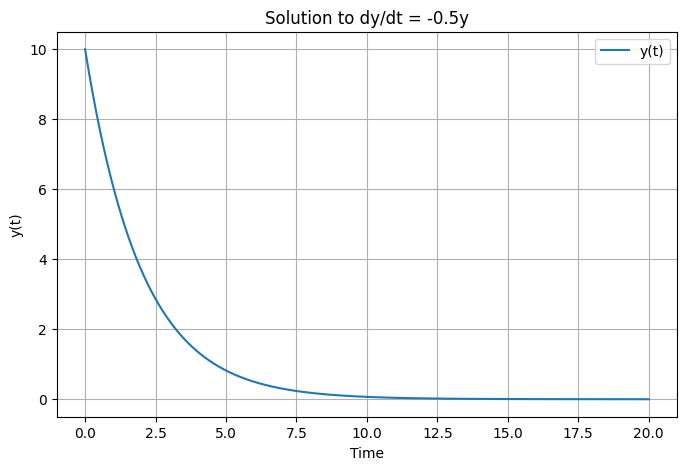

In [3]:
# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

plt.figure(figsize=(8, 5))
plt.plot(points["t"], points["y"], label='y(t)')
plt.xlabel('Time')
plt.ylabel('y(t)')
plt.title('Solution to dy/dt = -0.5y')
plt.grid(True)
plt.legend()
plt.show()

Computing trajectory...


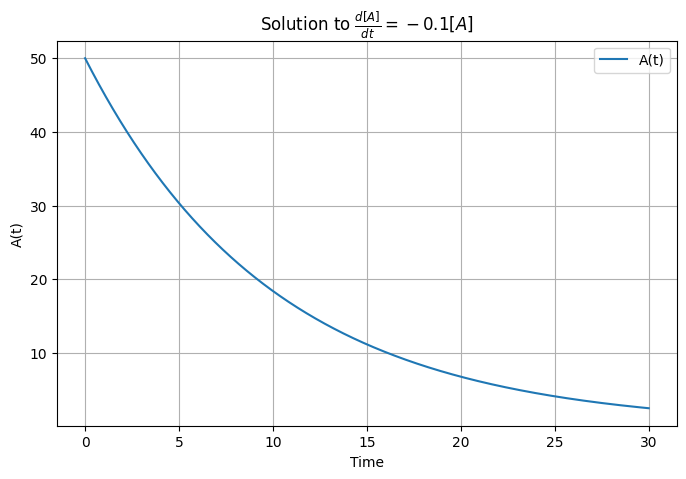

In [4]:
# Exercise

DSargs = dst.args(name="Exercise ODE")

pars = {"k" : 0.1,}
varspecs = {"A" : "-k*A",}
ics = {"A" : "50",}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics

# Solving the system
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
ode_sys.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

plt.figure(figsize=(8, 5))
plt.plot(points["t"], points["A"], label='A(t)')
plt.xlabel('Time')
plt.ylabel('A(t)')
plt.title(r'Solution to $\frac{d[A]}{dt} = -0.1[A]$')
plt.grid(True)
plt.legend()
plt.show()

Computing trajectory...


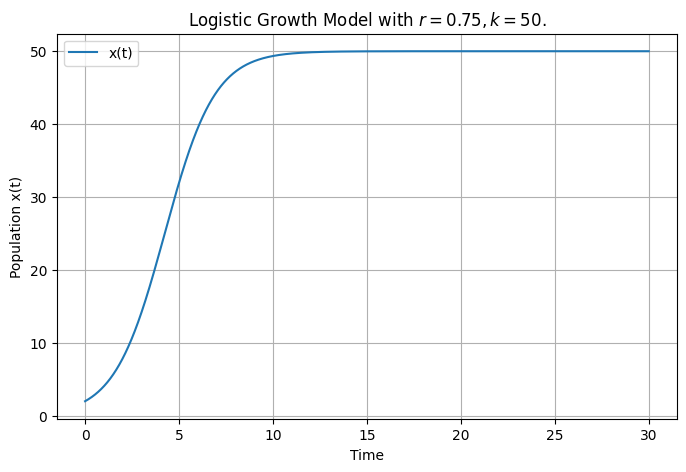

In [14]:
# Logistic Growth Model

DSargs = dst.args(name="Logistic Growth")
r = 0.75; k = 50
pars = {"r": r, "k": k,}
varspecs = {"x": "r*x*(1-x/k)",}
ics = {"x": 2,}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics

# Solving ODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

plt.figure(figsize=(8, 5))
plt.plot(points["t"], points["x"], label='x(t)')
plt.xlabel('Time')
plt.ylabel('Population x(t)')
plt.title(f'Logistic Growth Model with $r={r}, k={k}$.')
plt.grid(True)
plt.legend()
plt.show()

Computing continuation curve in parameter h...

Checking...
  |q| = 1.000000
  <p,q> = 1.000000
  |Aq| = 0.000000
  |transpose(A)p| = 0.000000

LP Point found 
0 : 
x  =  0.499999992397484
h  =  0.18749999999999992

Eigenvalues = 

     (0.000000,0.000000)


a = 0.7499999999394564



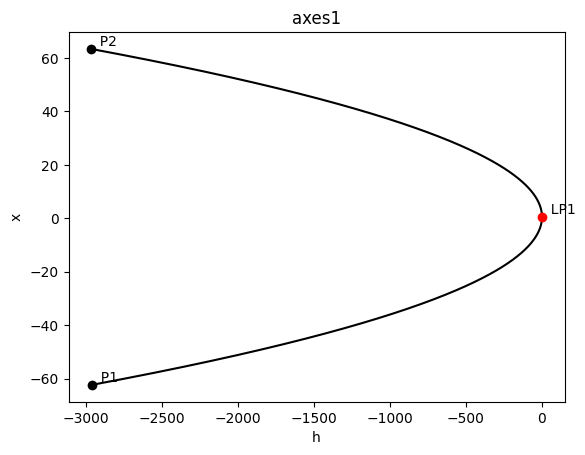

In [65]:
# Bifurcation Value for Logistic Growth
DSargs = dst.args(name="Logistic Growth with Bifurcation")

# ODE
r = 0.75; k = 1
DSargs.pars = {"r": r, "k": k, "h": 0}
DSargs.varspecs = {"x": "r*x*(1-x/k)-h"}
DSargs.ics = {"x": 10}
DSargs.xdomain = {"x": [0, 50]}
DSargs.tdata = [0, 100]

# Continuation Curve
ode = dst.Generator.Vode_ODEsystem(DSargs)
PC = dst.ContClass(ode)
PCargs = dst.args(name="EQ1", type="EP-C")
PCargs.freepars = ["h"]
PCargs.MaxNumPoints = 3000
PCargs.StepSize = 0.001
PCargs.MaxStepSize = 1.0
PCargs.MinStepSize = 1e-5
PCargs.LocBifPoints = ["LP"]
PCargs.verbosity = 2
PC.newCurve(PCargs)

print("Computing continuation curve in parameter h...")
PC["EQ1"].forward()
PC["EQ1"].backward()

# Plot
PC["EQ1"].display(("h", "x"), stability=True)